# ResNet-56 na CIFAR-10


In [38]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
import json
from pathlib import Path

import torch
import torchvision

SAVE_TO_DRIVE = False
DRIVE_SYNC_EVERY_EPOCHS = 10
RUN_DRY_RUN = True
UPLOAD_CIFAR10 = False
RESUME_CHECKPOINT = ""  # np. "/content/drive/MyDrive/resnet56-cifar10/checkpoints/2026.../last_model.pth"

if not torch.cuda.is_available():
    raise RuntimeError("Włącz GPU w ustawieniach środowiska wykonawczego Colaba.")

LOCAL_ROOT = Path("/content/resnet56-cifar10")
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

DRIVE_ROOT = None
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/resnet56-cifar10")
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

DATA_DIR = Path("/content/resnet56-cifar10-data")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"PyTorch: {torch.__version__}, torchvision: {torchvision.__version__}")

GPU: Tesla T4
PyTorch: 2.14.1+cu130, torchvision: 0.29.1+cu130


## Konfiguracja i funkcje pomocnicze

In [25]:
CONFIG = json.loads(r'''
{
  "seed": 42,
  "batch_size": 128,
  "num_workers": 2,
  "learning_rate": 0.1,
  "momentum": 0.9,
  "weight_decay": 0.0001,
  "milestones": [32000, 48000],
  "gamma": 0.1,
  "max_steps": 64000,
  "reference_error_pct": 6.97
}
''')
CONFIG_PATH = LOCAL_ROOT / "config.json"
CONFIG_PATH.write_text(json.dumps(CONFIG, indent=2) + "\n")

240

In [26]:
import csv
import os
import random
import shutil

import numpy as np
import torch


def setup(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def seed_worker(_worker_id):
    seed = torch.initial_seed() % (2**32)
    random.seed(seed)
    np.random.seed(seed)


def save_checkpoint(state, path):
    temporary = path.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(path)


def sync_to_drive(local_logs, local_checkpoints, drive_root, run_id):
    if drive_root is None:
        return
    target_logs = drive_root / "logs" / run_id
    target_ckpts = drive_root / "checkpoints" / run_id
    target_logs.mkdir(parents=True, exist_ok=True)
    target_ckpts.mkdir(parents=True, exist_ok=True)
    for src_dir, dst_dir in ((local_logs, target_logs), (local_checkpoints, target_ckpts)):
        for item in src_dir.iterdir():
            if item.is_file() and not item.name.endswith(".tmp"):
                shutil.copy2(item, dst_dir / item.name)


def save_metrics(history, directory):
    with (directory / "metrics.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)


def plot_metrics(history, directory):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    for metric, label in (("loss", "Loss"), ("error_pct", "Error rate (%)")):
        figure, axes = plt.subplots()
        for split in ("train", "test"):
            axes.plot(
                [row["step"] for row in history],
                [row[f"{split}_{metric}"] for row in history],
                marker=".", label=split,
            )
        axes.set(xlabel="Optimizer steps", ylabel=label)
        axes.legend()
        figure.tight_layout()
        figure.savefig(directory / f"{metric}.png", dpi=150)
        plt.close(figure)

## Model i weryfikacja przed treningiem

In [27]:
import torch
from torch import nn
from torch.nn import functional as F


class BasicBlock(nn.Module):
    def __init__(self, in_channels, channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
        self.stride = stride
        self.channel_padding = (channels - in_channels) // 2

    def forward(self, x):
        shortcut = x
        if self.stride != 1:
            shortcut = x[:, :, ::self.stride, ::self.stride]
            shortcut = F.pad(shortcut, (0, 0, 0, 0, self.channel_padding, self.channel_padding))
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)) + shortcut)


class ResNet56(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.layer1 = self._stage(16, 16, 1)
        self.layer2 = self._stage(16, 32, 2)
        self.layer3 = self._stage(32, 64, 2)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 10)
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

    @staticmethod
    def _stage(in_channels, channels, stride):
        return nn.Sequential(
            BasicBlock(in_channels, channels, stride),
            *(BasicBlock(channels, channels) for _ in range(8)),
        )

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layer3(self.layer2(self.layer1(x)))
        return self.fc(self.pool(x).flatten(1))


def verify_model(model, device):
    count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    model.eval()
    with torch.inference_mode():
        shape = tuple(model(torch.randn(2, 3, 32, 32, device=device)).shape)
    if count != 853018 or shape != (2, 10):
        raise RuntimeError(f"Unexpected model: {count} parameters, output {shape}")
    print(f"{count:,} parameters, output {shape} on {device}", flush=True)

In [28]:
device = setup(CONFIG["seed"])
verify_model(ResNet56().to(device), device)

853,018 parameters, output (2, 10) on cuda


## CIFAR-10 i pętla treningowa

In [29]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.datasets.utils import check_integrity


def prepare_cifar10(data_dir, upload_manual=False):
    cifar10 = datasets.CIFAR10
    archive = data_dir / cifar10.filename
    data_dir.mkdir(parents=True, exist_ok=True)
    if upload_manual and not (data_dir / cifar10.base_folder / "test_batch").is_file():
        from google.colab import files
        uploaded = files.upload()
        contents = uploaded.get(cifar10.filename)
        if contents is None:
            raise ValueError(f"Wgraj plik {cifar10.filename}.")
        pending = archive.with_suffix(".upload")
        pending.write_bytes(contents)
        if not check_integrity(pending, cifar10.tgz_md5):
            pending.unlink()
            raise ValueError("Archiwum CIFAR-10 jest niekompletne lub ma nieprawidłową sumę MD5.")
        pending.replace(archive)


def make_loaders(root, batch_size, workers, train_generator, test_generator):
    normalize = transforms.Normalize(
        (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)
    )
    train = datasets.CIFAR10(
        root, train=True, download=True,
        transform=transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.ToTensor(),
            normalize,
        ]),
    )
    test = datasets.CIFAR10(
        root, train=False, download=True,
        transform=transforms.Compose([transforms.ToTensor(), normalize]),
    )
    options = dict(
        batch_size=batch_size,
        num_workers=workers,
        pin_memory=True,
        persistent_workers=workers > 0,
        worker_init_fn=seed_worker,
    )
    return (
        DataLoader(train, shuffle=True, generator=train_generator, **options),
        DataLoader(test, shuffle=False, generator=test_generator, **options),
    )

In [30]:
prepare_cifar10(DATA_DIR, upload_manual=UPLOAD_CIFAR10)

In [31]:
import argparse
import json
import time
from datetime import datetime, timezone
from itertools import islice
from pathlib import Path

import torch
from torch import nn
from tqdm.auto import tqdm


def run_epoch(model, batches, device, criterion, optimizer=None, scheduler=None):
    training = optimizer is not None
    model.train(training)
    totals = torch.zeros(2, device=device)
    samples = 0
    with torch.set_grad_enabled(training):
        for images, targets in batches:
            images = images.to(device, non_blocking=device.type == "cuda")
            targets = targets.to(device, non_blocking=device.type == "cuda")
            if training:
                optimizer.zero_grad(set_to_none=True)
            scores = model(images)
            loss = criterion(scores, targets)
            if training:
                loss.backward()
                optimizer.step()
                scheduler.step()
            size = targets.size(0)
            totals[0] += loss.detach() * size
            totals[1] += (scores.detach().argmax(1) != targets).sum()
            samples += size
    loss_sum, errors = totals.tolist()
    return loss_sum / samples, 100 * errors / samples


def train_cifar10(argv):
    parser = argparse.ArgumentParser(description="Train ResNet-56 on CIFAR-10.")
    parser.add_argument("--config", type=Path, default=LOCAL_ROOT / "config.json")
    parser.add_argument("--data-dir", type=Path, default=DATA_DIR)
    parser.add_argument("--dry-run", action="store_true", help="Run one train/test epoch.")
    parser.add_argument("--resume", type=str, default="", help="Path to checkpoint to resume from.")
    args = parser.parse_args(argv)

    config = json.loads(args.config.read_text())
    seed = config["seed"]
    device = setup(seed)
    model = ResNet56().to(device)
    verify_model(model, device)

    train, test = make_loaders(
        args.data_dir, config["batch_size"], config["num_workers"],
        torch.Generator().manual_seed(seed), torch.Generator().manual_seed(seed + 1),
    )
    optimizer = torch.optim.SGD(
        model.parameters(), lr=config["learning_rate"],
        momentum=config["momentum"], weight_decay=config["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.MultiStepLR(
        optimizer, milestones=config["milestones"], gamma=config["gamma"],
    )
    criterion = nn.CrossEntropyLoss()

    history = []
    best_error = float("inf")
    step = 0
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    if args.dry_run:
        run_id = f"dry-run-{run_id}"

    if args.resume:
        ckpt_path = Path(args.resume)
        if not ckpt_path.is_file():
            raise FileNotFoundError(f"Nie znaleziono checkpointu: {ckpt_path}")
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        step = ckpt["step"]
        best_error = ckpt["best_test_error_pct"]
        history = ckpt.get("history", [])
        run_id = ckpt.get("run_id", run_id)
        print(f"Wznowiono trening z {ckpt_path} od kroku {step} (best error: {best_error:.2f}%)", flush=True)

    limit = len(train) if args.dry_run else config["max_steps"]
    logs = LOCAL_ROOT / "logs" / run_id
    checkpoints = LOCAL_ROOT / "checkpoints" / run_id
    for directory in (logs, checkpoints):
        directory.mkdir(parents=True, exist_ok=True)
    (logs / "config.json").write_text(json.dumps(config, indent=2) + "\n")
    print(f"Logs: {logs} | steps: {step} -> {limit}", flush=True)

    test_error = history[-1]["test_error_pct"] if history else float("inf")
    train_start_time = time.perf_counter()

    progress_bar = tqdm(
        total=limit,
        initial=step,
        desc="Trening ResNet-56",
        unit="step",
        dynamic_ncols=True,
    )

    while step < limit:
        epoch_start_time = time.perf_counter()
        steps = min(len(train), limit - step)
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_error = run_epoch(
            model, islice(train, steps), device, criterion, optimizer, scheduler,
        )
        step += steps
        with torch.inference_mode():
            test_loss, test_error = run_epoch(model, test, device, criterion)

        epoch_duration = time.perf_counter() - epoch_start_time
        total_elapsed = time.perf_counter() - train_start_time
        epoch = len(history) + 1

        history.append(dict(
            epoch=epoch, step=step, lr_start=lr, lr_next=optimizer.param_groups[0]["lr"],
            train_loss=train_loss, test_loss=test_loss,
            train_error_pct=train_error, test_error_pct=test_error,
            epoch_time_sec=round(epoch_duration, 2),
        ))
        is_best = test_error < best_error
        best_error = min(best_error, test_error)
        state = dict(
            model=model.state_dict(),
            optimizer=optimizer.state_dict(),
            scheduler=scheduler.state_dict(),
            epoch=epoch,
            step=step,
            best_test_error_pct=best_error,
            history=history,
            run_id=run_id,
            config=config,
        )
        if is_best:
            save_checkpoint(state, checkpoints / "best_model.pth")
        save_checkpoint(state, checkpoints / "last_model.pth")
        save_metrics(history, logs)

        if not args.dry_run and DRIVE_ROOT is not None and (epoch % DRIVE_SYNC_EVERY_EPOCHS == 0 or is_best):
            sync_to_drive(logs, checkpoints, DRIVE_ROOT, run_id)

        progress_bar.update(steps)
        progress_bar.set_postfix(
            ep=epoch,
            err=f"{test_error:.2f}%",
            best=f"{best_error:.2f}%",
            lr=f"{lr:.0e}",
        )
        tqdm.write(
            f"Epoch {epoch:03d} | step {step:5d}/{limit} | "
            f"czas epoki: {epoch_duration:.1f}s (łącznie: {total_elapsed/60:.1f} min) | "
            f"train err: {train_error:.2f}% | test err: {test_error:.2f}% (best: {best_error:.2f}%)"
        )

    progress_bar.close()

    plot_metrics(history, logs)
    summary = dict(
        device=str(device),
        dry_run=args.dry_run,
        steps=step,
        total_time_minutes=round((time.perf_counter() - train_start_time) / 60, 2),
        best_test_error_pct=best_error,
        last_test_error_pct=test_error,
    )
    if not args.dry_run:
        reference = config["reference_error_pct"]
        summary["reference_error_pct"] = reference
        summary["best_delta_percentage_points"] = round(best_error - reference, 6)
        summary["last_delta_percentage_points"] = round(test_error - reference, 6)
    (logs / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")

    if not args.dry_run and DRIVE_ROOT is not None:
        sync_to_drive(logs, checkpoints, DRIVE_ROOT, run_id)

    print(json.dumps(summary, indent=2), flush=True)
    return logs, checkpoints

## Epoka próbna

In [32]:
!curl -L -o /content/resnet56-cifar10-data/cifar-10-python.tar.gz "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/main/cifar-10-python.tar.gz"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1001  100  1001    0     0   5952      0 --:--:-- --:--:-- --:--:--  5958
100  162M  100  162M    0     0  43.7M      0  0:00:03  0:00:03 --:--:-- 55.2M


In [33]:
base_arguments = ["--config", str(CONFIG_PATH), "--data-dir", str(DATA_DIR)]
if RUN_DRY_RUN and not RESUME_CHECKPOINT:
    dry_logs, dry_checkpoints = train_cifar10([*base_arguments, "--dry-run"])

853,018 parameters, output (2, 10) on cuda
Logs: /content/resnet56-cifar10/logs/dry-run-20261124T104610865833Z | steps: 0 -> 391


Trening ResNet-56:   0%|          | 0/391 [00:00<?, ?step/s]

Epoch 001 | step   391/391 | czas epoki: 36.4s (łącznie: 0.6 min) | train err: 88.90% | test err: 87.61% (best: 87.61%)
{
  "device": "cuda",
  "dry_run": true,
  "steps": 391,
  "total_time_minutes": 0.61,
  "best_test_error_pct": 87.61,
  "last_test_error_pct": 87.61
}


## Pełny trening

In [34]:
train_arguments = list(base_arguments)
if RESUME_CHECKPOINT:
    train_arguments.extend(["--resume", RESUME_CHECKPOINT])
log_dir, checkpoint_dir = train_cifar10(train_arguments)

853,018 parameters, output (2, 10) on cuda
Logs: /content/resnet56-cifar10/logs/20261124T104649529326Z | steps: 0 -> 64000


Trening ResNet-56:   0%|          | 0/64000 [00:00<?, ?step/s]

Epoch 001 | step   391/64000 | czas epoki: 35.1s (łącznie: 0.6 min) | train err: 88.90% | test err: 87.61% (best: 87.61%)
Epoch 002 | step   782/64000 | czas epoki: 35.4s (łącznie: 1.2 min) | train err: 83.84% | test err: 70.71% (best: 70.71%)
Epoch 003 | step  1173/64000 | czas epoki: 35.9s (łącznie: 1.8 min) | train err: 63.39% | test err: 56.82% (best: 56.82%)
Epoch 004 | step  1564/64000 | czas epoki: 34.8s (łącznie: 2.4 min) | train err: 48.40% | test err: 56.84% (best: 56.82%)
Epoch 005 | step  1955/64000 | czas epoki: 35.5s (łącznie: 3.0 min) | train err: 38.35% | test err: 37.10% (best: 37.10%)
Epoch 006 | step  2346/64000 | czas epoki: 35.9s (łącznie: 3.6 min) | train err: 32.04% | test err: 30.28% (best: 30.28%)
Epoch 007 | step  2737/64000 | czas epoki: 34.9s (łącznie: 4.1 min) | train err: 27.76% | test err: 28.96% (best: 28.96%)
Epoch 008 | step  3128/64000 | czas epoki: 35.6s (łącznie: 4.7 min) | train err: 24.89% | test err: 33.14% (best: 28.96%)
Epoch 009 | step  3519/6

## Wynik i eksport

Podsumowanie podaje najlepszy i końcowy błąd testowy oraz różnicę w punktach procentowych
względem 6,97% z tabeli 6. [Artykuł He i in.](https://arxiv.org/abs/1512.03385)

{
  "device": "cuda",
  "dry_run": false,
  "steps": 64000,
  "total_time_minutes": 97.49,
  "best_test_error_pct": 7.76,
  "last_test_error_pct": 7.76,
  "reference_error_pct": 6.97,
  "best_delta_percentage_points": 0.79,
  "last_delta_percentage_points": 0.79
}



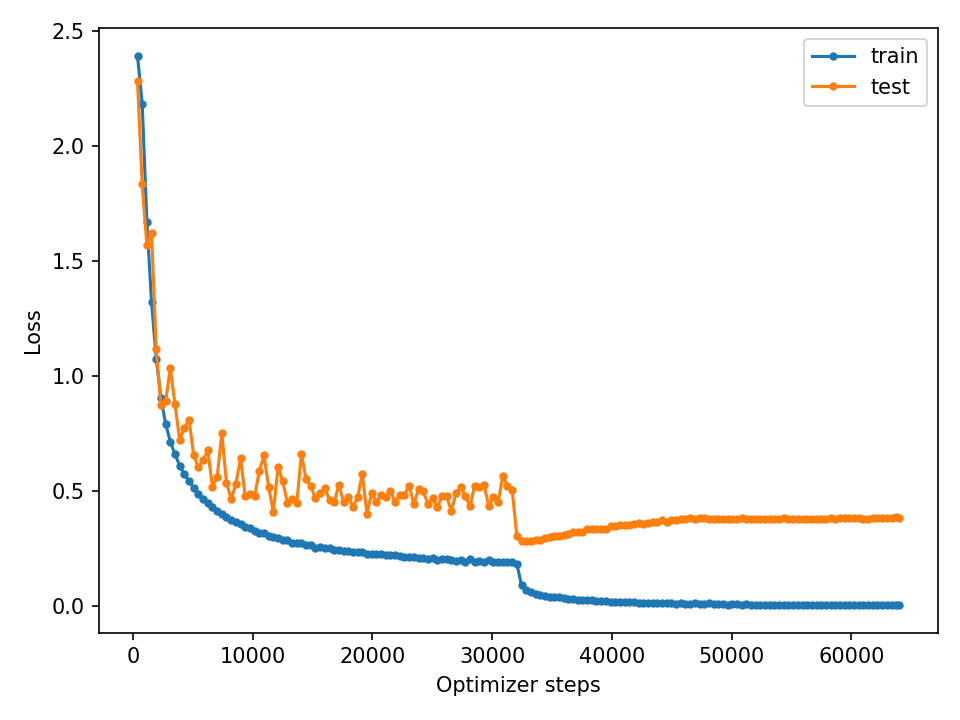

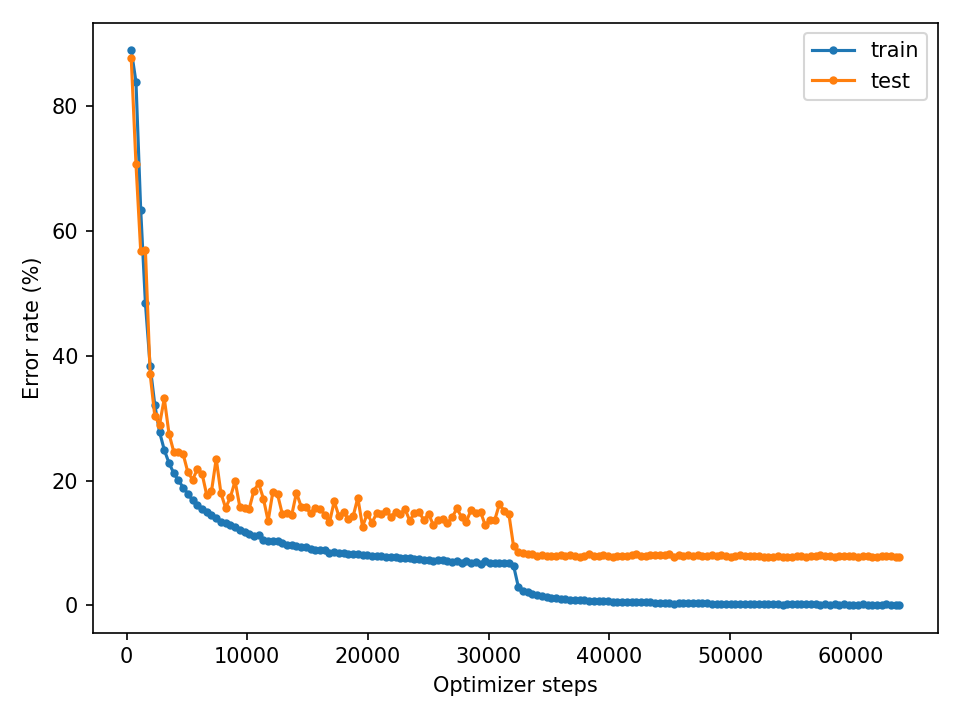

In [35]:
from IPython.display import Image, display

print((log_dir / "summary.json").read_text())
for filename in ("loss.png", "error_pct.png"):
    display(Image(filename=str(log_dir / filename)))

In [36]:
from zipfile import ZIP_DEFLATED, ZipFile
from google.colab import files

archive = LOCAL_ROOT / f"{log_dir.name}-results.zip"
with ZipFile(archive, "w", ZIP_DEFLATED) as output:
    for directory in (log_dir, checkpoint_dir):
        for artifact in sorted(directory.iterdir()):
            output.write(artifact, artifact.relative_to(LOCAL_ROOT))
files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
import csv
import json
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets, transforms

# Wczytanie historii treningu i podsumowania
with (log_dir / "metrics.csv").open() as f:
    rows = list(csv.DictReader(f))
summary = json.loads((log_dir / "summary.json").read_text())

steps = np.array([int(r["step"]) for r in rows]) / 1000.0  # w tysiącach kroków (k)
epochs = np.array([int(r["epoch"]) for r in rows])
train_err = np.array([float(r["train_error_pct"]) for r in rows])
test_err = np.array([float(r["test_error_pct"]) for r in rows])
train_loss = np.array([float(r["train_loss"]) for r in rows])
test_loss = np.array([float(r["test_loss"]) for r in rows])
lrs = np.array([float(r["lr_start"]) for r in rows])

best_idx = int(np.argmin(test_err))
best_step = steps[best_idx]
best_val = test_err[best_idx]
ref_val = summary.get("reference_error_pct", 6.97)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=130)
fig.suptitle("ResNet-56 na CIFAR-10 — Analiza treningu (He et al., 2015)", fontsize=15, fontweight="bold", y=0.98)

# 1. Krzywe błędu (styl jak na Fig. 6 w artykule He et al.)
ax = axes[0, 0]
ax.plot(steps, train_err, linestyle="--", color="#1f77b4", alpha=0.8, label="Train error (%)")
ax.plot(steps, test_err, linewidth=2.2, color="#d62728", label="Test error (%)")
ax.axhline(ref_val, color="#2ca02c", linestyle=":", linewidth=1.6, label=f"He et al. ref ({ref_val:.2f}%)")
ax.scatter([best_step], [best_val], color="#d62728", zorder=5, s=60)
ax.annotate(
    f"Best: {best_val:.2f}%\n(krok {best_step:.1f}k)",
    xy=(best_step, best_val),
    xytext=(best_step - 14, best_val + 4.5),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=1),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="#fff8dc", ec="#d62728", lw=0.8),
)
for m in (32, 48):
    ax.axvline(m, color="gray", linestyle="-.", alpha=0.45, lw=1)
ax.set_title("Krzywa błędu klasyfikacji (Train vs Test)", fontweight="bold")
ax.set_xlabel("Iteracje optymalizatora (×10³)")
ax.set_ylabel("Błąd klasyfikacji (%)")
ax.set_ylim(0, max(25, test_err[1] * 1.1))
ax.legend(loc="upper right", frameon=True)

# 2. Funkcja straty (Cross-Entropy Loss)
ax = axes[0, 1]
ax.plot(steps, train_loss, linestyle="--", color="#1f77b4", alpha=0.8, label="Train loss")
ax.plot(steps, test_loss, linewidth=2.2, color="#ff7f0e", label="Test loss")
for m in (32, 48):
    ax.axvline(m, color="gray", linestyle="-.", alpha=0.45, lw=1)
ax.set_title("Funkcja straty (Cross-Entropy Loss)", fontweight="bold")
ax.set_xlabel("Iteracje optymalizatora (×10³)")
ax.set_ylabel("Loss")
ax.legend(loc="upper right", frameon=True)

# 3. Luka generalizacji (Overfitting gap) + Harmonogram LR
ax = axes[1, 0]
gap = test_err - train_err
ax.fill_between(steps, 0, gap, color="#9467bd", alpha=0.25)
ax.plot(steps, gap, color="#9467bd", linewidth=1.8, label="Luka generalizacji (Test − Train err)")
ax.set_title("Luka generalizacji i harmonogram Learning Rate", fontweight="bold")
ax.set_xlabel("Iteracje optymalizatora (×10³)")
ax.set_ylabel("Różnica błędu (p.p.)", color="#9467bd")
ax.tick_params(axis="y", labelcolor="#9467bd")

ax_lr = ax.twinx()
ax_lr.step(steps, lrs, where="post", color="#17becf", linestyle="--", linewidth=1.8, label="Learning rate")
ax_lr.set_yscale("log")
ax_lr.set_ylabel("Learning rate (skala log)", color="#17becf")
ax_lr.tick_params(axis="y", labelcolor="#17becf")
ax_lr.grid(False)

# 4. Macierz pomyłek (Confusion Matrix) na zbiorze testowym dla najlepszego modelu
ax = axes[1, 1]
best_model = ResNet56().to(device)
best_ckpt = torch.load(checkpoint_dir / "best_model.pth", map_location=device)
best_model.load_state_dict(best_ckpt["model"])
best_model.eval()

normalize = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=transforms.Compose([transforms.ToTensor(), normalize]))
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)

cm = np.zeros((10, 10), dtype=int)
with torch.inference_mode():
    for imgs, lbls in test_loader:
        preds = best_model(imgs.to(device)).argmax(1).cpu().numpy()
        for t, p in zip(lbls.numpy(), preds):
            cm[t, p] += 1

cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100.0
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
classes = test_ds.classes
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=40, ha="right", fontsize=8.5)
ax.set_yticklabels(classes, fontsize=8.5)
for i in range(10):
    for j in range(10):
        val = cm_pct[i, j]
        if val >= 2.0 or i == j:
            ax.text(j, i, f"{val:.0f}", ha="center", va="center",
                    color="white" if val > 55 else "black", fontsize=7.5)
ax.set_title(f"Macierz pomyłek (%) — Najlepszy model ({best_val:.2f}% err)", fontweight="bold")
ax.set_xlabel("Predykcja modelu")
ax.set_ylabel("Prawdziwa klasa")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout(rect=[0, 0, 1, 0.96])
dashboard_path = log_dir / "training_dashboard.png"
plt.savefig(dashboard_path, dpi=300)
plt.show()
print(f"Zapisano dashboard wykresów do: {dashboard_path}")

Zapisano dashboard wykresów do: /content/resnet56-cifar10/logs/20261124T104649529326Z/training_dashboard.png


In [39]:
!cp -r /content/resnet56-cifar10 /content/drive/MyDrive/